# Chapter 9: Unsupervised Learning — K-Means Clustering

In this notebook, we explore **K-Means Clustering** using Scikit-Learn:
1. **Generating Unlabeled Data** (simulating realistic clusters)
2. **Fitting K-Means** and inspecting the cluster labels and centroids
3. **Visualizing Decision Boundaries (Voronoi Tessellation)**
4. **Predicting New Instances (`predict`)**
5. **Transforming Features into Distances (`transform` / Soft Clustering)**
6. **Evaluating Optimal $k$ with Inertia & the Elbow Method**


In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Styling
%matplotlib inline
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## 1. Generating Synthetic Unlabeled Data

We generate 2,000 2D data points around 5 cluster centers using `make_blobs`.
In unsupervised learning, we discard the true labels ($y$) and work purely with the feature matrix $X$.


In [2]:
# Define 5 blob centers and their standard deviations
blob_centers = np.array([
    [ 0.2,  2.3],
    [-1.5,  2.3],
    [-2.8,  1.8],
    [-2.8,  2.8],
    [-2.8,  1.3]
])
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])

# Generate data (we drop y because clustering is unsupervised)
X, y = make_blobs(n_samples=2000, centers=blob_centers, cluster_std=blob_std, random_state=7)

print(f"Dataset shape: {X.shape}")
print(f"First 5 instances:\n{X[:5]}")


Dataset shape: (2000, 2)
First 5 instances:
[[-2.69823941  1.3454702 ]
 [-2.87459835  1.8097575 ]
 [ 0.96077126  1.17046777]
 [-2.94032324  1.80224569]
 [-2.72483644  1.68358492]]


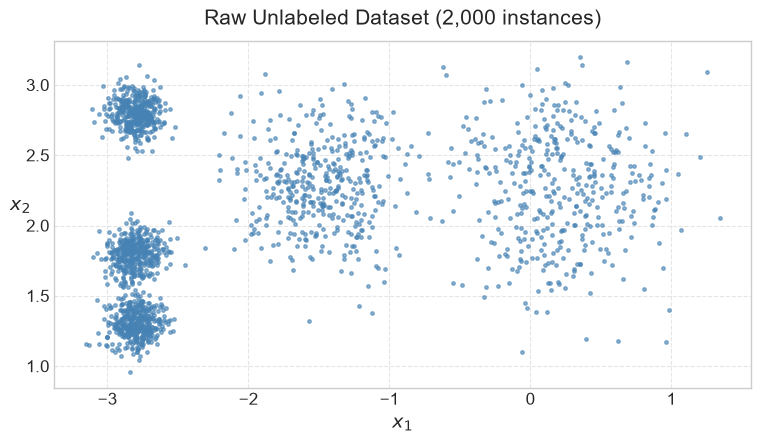

In [3]:
# Visualizing the raw, unlabeled data
plt.figure(figsize=(9, 4.5))
plt.scatter(X[:, 0], X[:, 1], c="steelblue", marker=".", s=25, alpha=0.6)
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.title("Raw Unlabeled Dataset (2,000 instances)", fontsize=15, pad=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


## 2. Fitting K-Means Clustering ($k = 5$)

Let's train a `KMeans` clusterer to find the 5 clusters.
* `n_clusters=5`: We want to partition the data into 5 clusters.
* `fit_predict(X)`: Fits the model on $X$ and returns the assigned cluster label for each instance.


In [4]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=43, n_init=10)
y_pred = kmeans.fit_predict(X)

print("Cluster labels for instances:")
print("y_pred:", y_pred)
print("\nIs y_pred identical to kmeans.labels_?", y_pred is kmeans.labels_)


Cluster labels for instances:
y_pred: [4 0 1 ... 2 1 0]

Is y_pred identical to kmeans.labels_? True


### Inspecting the Cluster Centroids (`cluster_centers_`)

The algorithm found 5 centroids (mean coordinates of each cluster in 2D space):


In [5]:
print("Learned Centroids (cluster_centers_):")
print(kmeans.cluster_centers_)


Learned Centroids (cluster_centers_):
[[-2.80389616  1.80117999]
 [ 0.20876306  2.25551336]
 [-2.79290307  2.79641063]
 [-1.46679593  2.28585348]
 [-2.80037642  1.30082566]]


## 3. Visualizing Decision Boundaries (Voronoi Tessellation)

K-Means creates **linear decision boundaries** between neighboring centroids, partitioning space into **Voronoi cells**.
Any point falling within a cell is assigned to that cell's centroid.


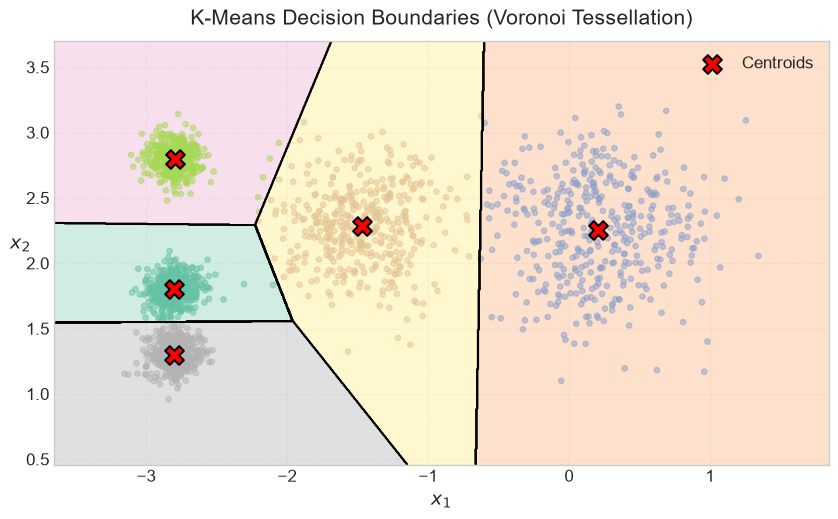

In [6]:
def plot_decision_boundaries(clusterer, X, resolution=1000):
    mins = X.min(axis=0) - 0.5
    maxs = X.max(axis=0) + 0.5
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot filled regions
    plt.contourf(xx, yy, Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                 cmap="Pastel2", alpha=0.6)
    # Plot boundary lines
    plt.contour(xx, yy, Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                colors='k', linewidths=1.2)

    # Plot data points
    plt.scatter(X[:, 0], X[:, 1], c=clusterer.labels_, cmap="Set2", s=15, alpha=0.5)

    # Plot centroids
    centers = clusterer.cluster_centers_
    plt.scatter(centers[:, 0], centers[:, 1],
                marker='X', s=180, c='red', edgecolor='black', linewidth=1.5,
                label='Centroids', zorder=10)

plt.figure(figsize=(10, 5.5))
plot_decision_boundaries(kmeans, X)
plt.title("K-Means Decision Boundaries (Voronoi Tessellation)", fontsize=15, pad=12)
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.legend(loc="upper right", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()


## 4. Predicting New Instances (`predict`) — Hard Clustering

Suppose we have 4 new unseen data points:
$$X_{new} = \begin{bmatrix} 0 & 2 \\ 3 & 2 \\ -3 & 3 \\ -3 & 2.5 \end{bmatrix}$$

`kmeans.predict(X_new)` assigns each point to the closest centroid (the Voronoi cell it falls into).


In [7]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
y_new_pred = kmeans.predict(X_new)

print("Predictions for X_new:")
for pt, cluster_id in zip(X_new, y_new_pred):
    print(f"  Point {pt}  -->  Cluster {cluster_id}")


Predictions for X_new:
  Point [0. 2.]  -->  Cluster 1
  Point [3. 2.]  -->  Cluster 1
  Point [-3.  3.]  -->  Cluster 2
  Point [-3.   2.5]  -->  Cluster 2


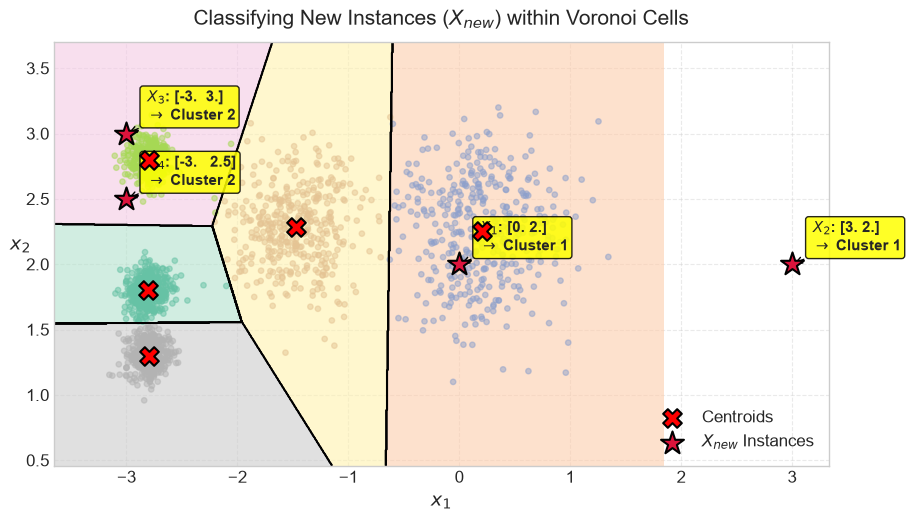

In [8]:
plt.figure(figsize=(10, 5.5))
plot_decision_boundaries(kmeans, X)

# Overlay the 4 new points with bright red stars
plt.scatter(X_new[:, 0], X_new[:, 1], marker="*", s=300, c="crimson",
            edgecolor="black", linewidth=1.5, zorder=20, label="$X_{new}$ Instances")

# Annotate each point
for i, pt in enumerate(X_new):
    plt.annotate(f" $X_{{{i+1}}}$: {pt}\n $\\to$ Cluster {y_new_pred[i]}",
                 xy=(pt[0], pt[1]), xytext=(pt[0] + 0.15, pt[1] + 0.1),
                 fontsize=11, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.85),
                 arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0", color="black"))

plt.title("Classifying New Instances ($X_{new}$) within Voronoi Cells", fontsize=15, pad=12)
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.legend(loc="lower right", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()


## 5. Distance to Centroids (`transform`) — Soft Clustering

While `predict()` only outputs the single winning cluster (**hard clustering**), `transform()` measures the **Euclidean distance from each point to every one of the 5 centroids** (**soft clustering**):


In [9]:
distances = kmeans.transform(X_new)
print("Distances to all 5 centroids for each X_new point:")
print(np.round(distances, 4))


Distances to all 5 centroids for each X_new point:
[[2.8109 0.33   2.9042 1.4944 2.8863]
 [5.8073 2.8029 5.8474 4.4759 5.8424]
 [1.2148 3.294  0.2904 1.6914 1.7109]
 [0.7258 3.2181 0.3616 1.5481 1.2157]]


In [10]:
# Let's inspect the first point: [0, 2]
p0 = X_new[0]
print(f"Point 1: {p0}")
print("Distances to centroids [0, 1, 2, 3, 4]:")
for c_idx, d in enumerate(distances[0]):
    print(f"  To Centroid {c_idx} {kmeans.cluster_centers_[c_idx]}: distance = {d:.4f}")

closest_cluster = np.argmin(distances[0])
print(f"\nSmallest distance is {distances[0][closest_cluster]:.4f} to Centroid {closest_cluster}!")
print(f"This is exactly why predict() returned Cluster {closest_cluster}.")


Point 1: [0. 2.]
Distances to centroids [0, 1, 2, 3, 4]:
  To Centroid 0 [-2.80389616  1.80117999]: distance = 2.8109
  To Centroid 1 [0.20876306 2.25551336]: distance = 0.3300
  To Centroid 2 [-2.79290307  2.79641063]: distance = 2.9042
  To Centroid 3 [-1.46679593  2.28585348]: distance = 1.4944
  To Centroid 4 [-2.80037642  1.30082566]: distance = 2.8863

Smallest distance is 0.3300 to Centroid 1!
This is exactly why predict() returned Cluster 1.


## 6. How to Choose the Optimal Number of Clusters ($k$)

### A. Inertia & The Elbow Method
* **Inertia** is the sum of squared distances of samples to their closest cluster center.
* Lower inertia means tighter, more compact clusters.
* However, inertia alone always decreases as $k$ grows. We look for the **"elbow"** where the rate of improvement slows down.


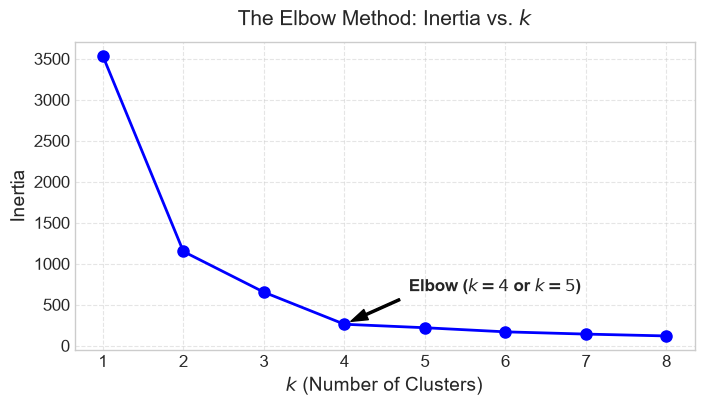

In [11]:
# Compute inertia for k = 1 to 8
k_range = range(1, 9)
kmeans_per_k = [KMeans(n_clusters=k_val, random_state=42, n_init=10).fit(X) for k_val in k_range]
inertias = [model.inertia_ for model in kmeans_per_k]

plt.figure(figsize=(8, 4))
plt.plot(k_range, inertias, "bo-", linewidth=2, markersize=8)
plt.xlabel("$k$ (Number of Clusters)", fontsize=14)
plt.ylabel("Inertia", fontsize=14)
plt.title("The Elbow Method: Inertia vs. $k$", fontsize=15, pad=12)
plt.annotate("Elbow ($k=4$ or $k=5$)",
             xy=(4, inertias[3]), xytext=(4.8, inertias[3] + 400),
             fontsize=12, fontweight="bold",
             arrowprops=dict(facecolor="black", shrink=0.1, width=1.5, headwidth=8))
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


### B. Silhouette Score

The **Silhouette Score** ranges from $-1$ to $+1$:
* $+1$: Points are dense within their cluster and far from other clusters.
* $0$: Points are on or close to the decision boundary.
* $-1$: Points may be assigned to the wrong cluster.


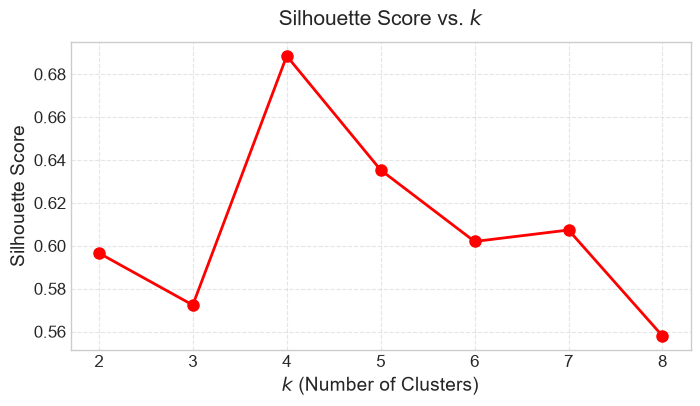

Optimal k based on maximum silhouette score: k = 4 (score = 0.6885)


In [12]:
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

plt.figure(figsize=(8, 4))
plt.plot(range(2, 9), silhouette_scores, "ro-", linewidth=2, markersize=8)
plt.xlabel("$k$ (Number of Clusters)", fontsize=14)
plt.ylabel("Silhouette Score", fontsize=14)
plt.title("Silhouette Score vs. $k$", fontsize=15, pad=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

best_k = range(2, 9)[np.argmax(silhouette_scores)]
print(f"Optimal k based on maximum silhouette score: k = {best_k} (score = {max(silhouette_scores):.4f})")


## Summary Checklist

| Operation | Code | Output / Role |
| :--- | :--- | :--- |
| **Fit & Assign** | `kmeans.fit_predict(X)` | Returns array of cluster labels for training data. |
| **Labels** | `kmeans.labels_` | The assigned cluster IDs for each sample in $X$. |
| **Centroids** | `kmeans.cluster_centers_` | The $(x, y)$ coordinate positions of the $k$ cluster centers. |
| **Hard Clustering** | `kmeans.predict(X_new)` | Assigns new points to their nearest centroid. |
| **Soft Clustering** | `kmeans.transform(X_new)` | Calculates Euclidean distance to all centroids (useful feature transform). |
| **Compactness** | `kmeans.inertia_` | Total within-cluster sum of squared distances. |
